<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/4%20-%20Redes%20Neurais/4.3_underfitting_overfitting_regularizacao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 4.3 — Underfitting, overfitting e regularização

No 4.2, medimos a acurácia nos mesmos dados usados no treino. Um modelo com muitos parâmetros pode acertar quase tudo nesses dados e ainda assim errar em dados novos. Este notebook mostra isso num problema de regressão com uma variável, em que dá para ver a curva que a rede aprendeu.

- **Underfitting** (subajuste) ocorre quando o modelo não consegue representar o padrão dos dados: erra no treino e na validação. Em geral, resolve-se aumentando a complexidade do modelo (em redes neurais, mais neurônios e camadas) ou treinando por mais épocas.
- **Overfitting** (sobreajuste) ocorre quando o modelo se ajusta demais aos dados de treino, inclusive ao ruído, e perde a capacidade de generalizar para dados novos: o custo de treino fica baixo e o de validação, alto.
- **Regularização** é o nome das técnicas que reduzem o overfitting. Aqui veremos o early stopping e a regularização L2.

O exemplo é uma adaptação do capítulo 1 do livro: Christopher M. Bishop. *Pattern Recognition and Machine Learning*. Springer, 2006.

## Objetivos

- Separar o custo de treino do custo de validação e reconhecer underfitting e overfitting nas curvas.
- Usar os controles interativos para variar neurônios, épocas, taxa de aprendizado e o fator de regularização $\lambda$.
- Aplicar early stopping e regularização L2 e ver o efeito da L2 sobre os pesos.

## Importação das bibliotecas

Além de PyTorch, NumPy e matplotlib, usamos o `ipywidgets` para os gráficos interativos (já instalado no Colab). Este notebook usa a GPU quando houver (`device`), mas roda em CPU: cada treino leva poucos segundos.

In [ ]:
import matplotlib.pyplot as plt
import ipywidgets as widgets

import numpy as np
import torch
from torch import nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

## Gerando dados sintéticos com ruído

A função verdadeira é $y = \sin(2\pi x)$ para $x \in [0, 1]$ (curva laranja nos gráficos). As amostras observadas têm ruído gaussiano:

$$y_n = \sin(2\pi x_n) + \varepsilon_n, \qquad \varepsilon_n \sim \mathcal{N}(0, \sigma^2)$$

com $\sigma$ = `noise_stdev` (padrão 0,3). Os valores de $x$ são sorteados, sem repetição, de uma grade de $2N + 20$ pontos: $N$ = `n_points` (padrão 15) para o **treino** e outros $N$ para a **validação**. A validação não é usada para ajustar os pesos, só para medir o custo em dados que o modelo não viu. A semente fixa (`rnd_seed`) faz os dados serem sempre os mesmos.

In [ ]:
def generate_dataset(n_points=15, noise_stdev=0.3, rnd_seed=20):
    torch.manual_seed(rnd_seed)

    # Ruído gaussiano: média zero, desvio padrão noise_stdev
    noise_mean = torch.zeros(n_points)

    # Função verdadeira, só para os gráficos
    x_true = torch.linspace(0.0, 1.0, 100)
    y_true = torch.sin(2.0 * np.pi * x_true)

    x_samples = torch.linspace(0.0, 1.0, 2 * n_points + 20)
    idx = torch.randperm(2 * n_points + 20)
    tra_idx = idx[:n_points]
    val_idx = idx[-n_points:]

    # Conjunto de validação, shape (N, 1)
    x_val = x_samples[val_idx].view(-1, 1)
    y_val = torch.sin(2.0 * np.pi * x_val[:, 0]) + torch.normal(noise_mean, noise_stdev)

    # Conjunto de treino, shape (N, 1)
    x_train = x_samples[tra_idx].view(-1, 1)
    y_train = torch.sin(2.0 * np.pi * x_train[:, 0]) + torch.normal(noise_mean, noise_stdev)

    # nn.MSELoss exige que a previsão (N, 1) e o alvo tenham o mesmo shape
    y_train = y_train.view(-1, 1)
    y_val = y_val.view(-1, 1)

    return x_true, y_true, x_train, y_train, x_val, y_val


x_true, y_true, x_train, y_train, x_val, y_val = generate_dataset()
print('x_train:', tuple(x_train.shape), ' y_train:', tuple(y_train.shape), ' x_val:', tuple(x_val.shape))
plt.plot(x_true, y_true, color='orange', label='função verdadeira')
plt.plot(x_train, y_train, 'x', color='blue', label='treino')
plt.plot(x_val, y_val, 'x', color='red', label='validação')
plt.xlabel('x'); plt.ylabel('y'); plt.grid(); plt.legend()
plt.show()

## Rede neural e procedimento de treino

`Net(n_hidden_neurons)` é uma rede com uma entrada, uma camada escondida de `n_hidden_neurons` neurônios com ativação sigmoide e uma saída linear: $\hat{y} = W_2\,\sigma(W_1 x + \boldsymbol{b}_1) + b_2$, com $3n + 1$ parâmetros para $n$ neurônios. Com `n_hidden_neurons = 0`, ela vira a regressão linear $\hat{y} = w_1 x + w_0$ do módulo 2.

`train_model` treina com o conjunto de treino inteiro a cada época e guarda, por época, o custo de treino e o de validação:

- função de custo: `nn.MSELoss`, o erro quadrático médio $\frac{1}{N}\sum_n (\hat{y}_n - y_n)^2$;
- otimizador: `torch.optim.SGD`, o gradiente descendente do 2.5. A cada época, `zero_grad()` zera os gradientes, `backward()` os calcula e `step()` atualiza cada parâmetro com $\theta \leftarrow \theta - \eta\,\partial E/\partial\theta$, com $\eta$ = `lr`. Como usamos todos os pontos de treino a cada passo, é o gradiente descendente em lote (batch). A taxa de aprendizado padrão é `lr = 0.4`: com valores menores o treino fica mais lento, e com 0,6 ou mais ele trava ou diverge nesta rede;
- regularização L2 com fator `reg_factor` ($\lambda$), somada ao custo de treino (detalhes na seção "Regularização L2");
- a validação é calculada com `model.eval()` e `torch.no_grad()`, porque não deve gerar gradientes nem alterar os pesos.

In [ ]:
class Net(nn.Module):
    def __init__(self, n_hidden_neurons):
        super().__init__()
        self.n_hidden = n_hidden_neurons
        if n_hidden_neurons == 0:
            self.linear01 = nn.Linear(in_features=1, out_features=1)
        else:
            self.linear01 = nn.Linear(in_features=1, out_features=n_hidden_neurons)
            self.linear02 = nn.Linear(in_features=n_hidden_neurons, out_features=1)

    def forward(self, x):
        if self.n_hidden == 0:
            x = self.linear01(x)
        else:
            x = self.linear01(x)
            x = torch.sigmoid(x)
            x = self.linear02(x)
        return x


def l2_penalty(model):
    '''Soma dos quadrados de todos os pesos (||W||^2); os bias não entram.'''
    return sum((p ** 2).sum() for name, p in model.named_parameters() if name.endswith('weight'))


def train_model(model, x_train, y_train, x_val, y_val, lr=0.4, reg_factor=0.0, n_epochs=100):
    criterion = nn.MSELoss()
    optimizer = torch.optim.SGD(params=model.parameters(), lr=lr)   # gradiente descendente, sem momentum

    # modelo e dados no mesmo device (GPU, se houver)
    model = model.to(device)
    x_train, y_train = x_train.to(device), y_train.to(device)
    x_val, y_val = x_val.to(device), y_val.to(device)

    train_losses = []
    val_losses = []
    for i in range(n_epochs):
        model.train()
        optimizer.zero_grad()
        train_pred = model(x_train)
        train_mse = criterion(train_pred, y_train)
        loss = train_mse + reg_factor / 2 * l2_penalty(model)   # E(w) = MSE + (λ/2)·||W||²
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_pred = model(x_val)
            val_mse = criterion(val_pred, y_val)

        # .item(): número Python, sem o grafo de gradientes
        train_losses.append(train_mse.item())
        val_losses.append(val_mse.item())

    # previsões finais, de volta na CPU para os gráficos
    model.eval()
    with torch.no_grad():
        train_pred = model(x_train).cpu()
        val_pred = model(x_val).cpu()
    return train_losses, val_losses, train_pred, val_pred

## Procedimentos para criação de gráficos interativos

`show_network_plots` gera os dados, cria uma rede nova (sempre com a mesma semente `model_seed`), treina e mostra dois gráficos:

- à esquerda, o custo (MSE) de treino (azul) e de validação (vermelho) a cada época; a linha tracejada marca a época com o menor custo de validação;
- à direita, a função verdadeira (laranja) e as previsões da rede para os pontos de treino e validação (círculos). Marque `t_train` e `t_test` para ver também os valores observados de treino e validação (x).

`showIt` cria os controles (sliders) e chama `widgets.interact`, que executa `show_network_plots` uma vez com os valores iniciais e de novo a cada mudança de um controle. No Colab ou no Jupyter, mova os sliders e observe; cada mudança treina uma rede nova, em poucos segundos (com 10000 épocas, cerca de 10 s).

In [ ]:
def show_network_plots(n_data=15, noise=0.3, neurons=16, epochs=5000, lr=0.4, L2_reg=0.0,
                       t_train=False, t_test=False, model_seed=1):
    global model

    x_true, y_true, x_train, y_train, x_val, y_val = generate_dataset(n_points=n_data, noise_stdev=noise)
    torch.manual_seed(model_seed)   # mesma inicialização dos pesos para qualquer combinação dos controles
    model = Net(neurons)
    tra_loss, val_loss, tra_pred, val_pred = train_model(model, x_train, y_train, x_val, y_val,
                                                         lr=lr, reg_factor=L2_reg, n_epochs=epochs)
    best = int(np.argmin(val_loss))

    fig = plt.figure(figsize=(15, 4))

    fig.add_subplot(1, 2, 1)
    plt.plot(tra_loss, color='blue', label='treino')
    plt.plot(val_loss, color='red', label='validação')
    plt.axvline(best, color='gray', ls='--', label=f'menor custo de validação (época {best + 1})')
    plt.ylim(0, 1.0)
    plt.xlabel('Época')
    plt.ylabel('Custo (MSE)')
    plt.grid()
    plt.legend()

    print('Custo final:  treino={:.5f},  validação={:.5f}'.format(tra_loss[-1], val_loss[-1]))
    print('Menor custo de validação: {:.5f}, na época {}'.format(val_loss[best], best + 1))

    fig.add_subplot(1, 2, 2)
    plt.plot(x_true.numpy(), y_true.numpy(), color='orange')
    plt.plot(x_train.numpy(), tra_pred.numpy(), 'o', color='blue', label='previsão no treino')
    plt.plot(x_val.numpy(), val_pred.numpy(), 'o', color='red', label='previsão na validação')
    if t_train:
        plt.plot(x_train.numpy(), y_train.numpy(), 'x', color='blue', label='y de treino')
    if t_test:
        plt.plot(x_val.numpy(), y_val.numpy(), 'x', color='red', label='y de validação')
    plt.ylim(-1.6, 1.6)
    plt.xlabel('x')
    plt.grid()
    plt.legend()
    plt.show()   # necessário para a figura aparecer dentro do widget


def showIt(n_data=15, noise=0.3, neurons=16, epochs=5000, lr=0.4, L2_reg=0.0, t_train=False, t_test=False):
    s_ndata = widgets.IntSlider(min=10, max=20, step=1, value=n_data, continuous_update=False)
    s_epochs = widgets.IntSlider(min=100, max=10000, step=100, value=epochs, continuous_update=False)
    s_neurons = widgets.IntSlider(min=0, max=32, step=1, value=neurons, continuous_update=False)

    s_noise = widgets.FloatSlider(min=0.1, max=0.5, step=0.1, value=noise, readout_format='.1f',
                                  continuous_update=False)
    s_lr = widgets.FloatSlider(min=0.05, max=0.5, step=0.05, value=lr, readout_format='.2f',
                               continuous_update=False)
    s_L2_reg = widgets.FloatSlider(min=0.0, max=0.002, step=0.0001, value=L2_reg, readout_format='.4f',
                                   continuous_update=False)

    widgets.interact(show_network_plots, n_data=s_ndata, epochs=s_epochs, noise=s_noise,
                     neurons=s_neurons, lr=s_lr, L2_reg=s_L2_reg,
                     t_train=widgets.Checkbox(value=t_train), t_test=widgets.Checkbox(value=t_test),
                     model_seed=widgets.fixed(1));

# Experimentos

## Underfitting

Com 16 neurônios e só 300 épocas, a rede ainda não aprendeu a forma da senoide: as previsões ficam perto de uma reta e o custo é alto no treino e na validação. Com o gradiente descendente, o custo quase não muda nessas primeiras centenas de épocas (os gradientes são pequenos no início) e só depois cai; mova o slider de épocas para 500 e veja a queda. Experimente também `neurons = 0` (regressão linear) com 5000 épocas: uma reta não representa a senoide, por mais que se treine.

Neste conjunto, o custo de validação fica abaixo do de treino no começo do treino. Isso é efeito da amostra pequena: os 15 valores de $x$ sorteados para a validação caíram em regiões onde $|\sin(2\pi x)|$ é menor (a variância de `y_val` é 0,42, contra 0,68 de `y_train`), e uma previsão próxima de uma reta erra menos ali.

In [ ]:
showIt(epochs=300)

## Overfitting

Com 5000 épocas, o custo de treino continua caindo (com uma queda brusca perto da época 3300, quando a rede passa a usar os pesos para passar perto de cada ponto), mas o custo de validação passa por um mínimo (linha tracejada) e depois volta a subir: a rede passa a seguir o ruído dos pontos de treino. Aqui o menor custo de validação é 0,097, na época 3324, e no fim do treino o custo é 0,039 no treino e 0,149 na validação. Marque `t_train` e veja que as previsões no treino se aproximam dos valores observados (x azuis), não da curva laranja.

In [ ]:
showIt()

## Early stopping

Early stopping (parada antecipada) é interromper o treino na época em que o custo de validação é mínimo. No experimento anterior, essa época aparece na linha tracejada e na mensagem "Menor custo de validação". Aqui treinamos só até perto dela (3300 épocas) e comparamos o custo de validação final com o do experimento de overfitting: 0,097, contra 0,149 com 5000 épocas.

In [ ]:
showIt(epochs=3300)

## Regularização L2

A regularização L2 acrescenta à função de custo um termo que penaliza pesos grandes. No livro do Bishop e no slide "Como combater o overfitting", a função de custo é

$$E(\boldsymbol{w}) = \frac{1}{2}\sum_{n=1}^N\left(\hat{y}(x_n,\boldsymbol{w})-y_n\right)^2 +\frac{\lambda}{2}\|\boldsymbol{W}\|^2$$

onde $N$ é o número de amostras de treino, $\hat{y}(x_n, \boldsymbol{w})$ é a previsão da rede para $x_n$, $\boldsymbol{W}$ são os pesos da rede (sem os bias), $\|\boldsymbol{W}\|^2 = \sum_j W_j^2$ é a soma dos quadrados de todos os pesos e $\lambda \ge 0$ é o fator de regularização (hiperparâmetro).

No código (`train_model`), o primeiro termo é o `nn.MSELoss`, que usa a **média** em vez de $\frac{1}{2}\sum$:

$$E_{\text{código}}(\boldsymbol{w}) = \frac{1}{N}\sum_{n=1}^N\left(\hat{y}(x_n,\boldsymbol{w})-y_n\right)^2 +\frac{\lambda}{2}\|\boldsymbol{W}\|^2$$

que é a linha `loss = train_mse + reg_factor / 2 * l2_penalty(model)`, com `reg_factor` $= \lambda$ (o controle `L2_reg`). As duas formas têm o mesmo mínimo quando os fatores correspondem: como $\frac{1}{2}\sum = \frac{N}{2}\cdot\frac{1}{N}\sum$, o $\lambda$ da fórmula do slide equivale a $\frac{N}{2}\lambda$ do código (com $N = 15$, `L2_reg = 0.0005` corresponde a $\lambda \approx 0{,}0038$ no slide).

O gradiente do termo de regularização em relação a cada peso é $\lambda W_j$: a cada passo, cada peso é puxado na direção de zero, proporcionalmente ao seu valor. Por isso a L2 também é chamada de **decaimento de pesos (weight decay)**. Os otimizadores do PyTorch têm o parâmetro `weight_decay=λ`, que soma $\lambda\,\theta$ ao gradiente de **todos** os parâmetros $\theta$, inclusive os bias; com o `optim.SGD`, usado aqui, isso equivale a somar $\frac{\lambda}{2}\|\boldsymbol{\theta}\|^2$ ao custo. Neste notebook, o termo é escrito explicitamente para que o código siga a fórmula.

Os gráficos de custo mostram só o MSE (sem o termo de regularização), para comparar treino e validação na mesma escala.

No experimento abaixo, com 5000 épocas e `L2_reg = 0.0005`, compare com o de overfitting: o custo de treino fica mais alto (0,213, contra 0,039), mas o de validação não volta a subir e termina em 0,118 (contra 0,149). A curva aprendida fica suave, próxima da senoide.

In [ ]:
showIt(L2_reg=0.0005)

## Histograma dos pesos

Para ver o efeito da L2 sobre os pesos, treinamos duas redes iguais (16 neurônios, 5000 épocas, mesma semente), uma sem regularização e outra com `L2_reg = 0.0005`, e comparamos a distribuição dos pesos (sem os bias) e o valor de $\|\boldsymbol{W}\|^2$.

In [ ]:
def trained_weights(L2_reg, neurons=16, epochs=5000, model_seed=1):
    x_true, y_true, x_train, y_train, x_val, y_val = generate_dataset()
    torch.manual_seed(model_seed)
    m = Net(neurons)
    train_model(m, x_train, y_train, x_val, y_val, lr=0.4, reg_factor=L2_reg, n_epochs=epochs)
    # .detach(): tensor sem gradiente; .cpu() antes de .numpy()
    ww = torch.cat([p.detach().cpu().view(-1) for name, p in m.named_parameters() if name.endswith('weight')])
    return ww.numpy()


w_noreg = trained_weights(0.0)
w_l2 = trained_weights(0.0005)
print('||W||² sem regularização: {:.2f}'.format((w_noreg ** 2).sum()))
print('||W||² com L2 = 0.0005:   {:.2f}'.format((w_l2 ** 2).sum()))

bins = np.linspace(min(w_noreg.min(), w_l2.min()), max(w_noreg.max(), w_l2.max()), 25)
plt.hist(w_noreg, bins=bins, alpha=0.6, label='sem regularização')
plt.hist(w_l2, bins=bins, alpha=0.6, label='L2_reg = 0.0005')
plt.xlabel('valor do peso')
plt.ylabel('número de pesos')
plt.legend()
plt.show()

Sem regularização, $\|\boldsymbol{W}\|^2 \approx 347$: um peso chega perto de $-12{,}6$, dois ficam perto de $-6$ e os demais entre $-3$ e $4$. Com `L2_reg = 0.0005`, $\|\boldsymbol{W}\|^2$ cai para cerca de 143: 31 dos 32 pesos ficam entre $-1{,}6$ e $1{,}9$ (um continua grande, perto de $-10{,}7$). Com pesos menores, as sigmoides da camada escondida ficam menos íngremes e a curva aprendida fica mais suave, seguindo menos o ruído dos pontos de treino.

# Exercícios

**1.** Complexidade do modelo. Sem regularização e com 5000 épocas, treine redes com 0, 1, 2, 4, 8, 16 e 32 neurônios na camada escondida (use `generate_dataset`, `Net` e `train_model`, com `torch.manual_seed(1)` antes de criar cada rede). Faça um gráfico do custo de treino e de validação **finais** em função do número de neurônios. Compare com o slide "Aumentando a complexidade do modelo": qual número de neurônios tem o menor custo de validação?

In [ ]:
neurons_list = [0, 1, 2, 4, 8, 16, 32]
x_true, y_true, x_train, y_train, x_val, y_val = generate_dataset()

# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

**2.** Escolha de $\lambda$. Com 16 neurônios e 5000 épocas, treine com `reg_factor` em `[0, 0.0001, 0.0002, 0.0003, 0.0005, 0.001, 0.002, 0.005]` e faça um gráfico dos custos de treino e de validação finais em função de $\lambda$. Qual $\lambda$ tem o menor custo de validação? O que acontece quando $\lambda$ é grande demais?

In [ ]:
lambdas = [0, 0.0001, 0.0002, 0.0003, 0.0005, 0.001, 0.002, 0.005]

# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

**3.** Acesse o [TensorFlow Playground](https://playground.tensorflow.org) e, usando apenas as 2 entradas $x_1$ e $x_2$, varie:

- o número de camadas;
- o número de neurônios em cada camada;
- o tipo de ativação;
- a taxa de aprendizado (learning rate);
- o tipo e o fator de regularização.

Resolva para o dataset "Spiral" (circulado na figura), com **Test loss abaixo de 0,1**. Procure a menor rede que separa a espiral, como proposto no slide "Redes neurais na prática".

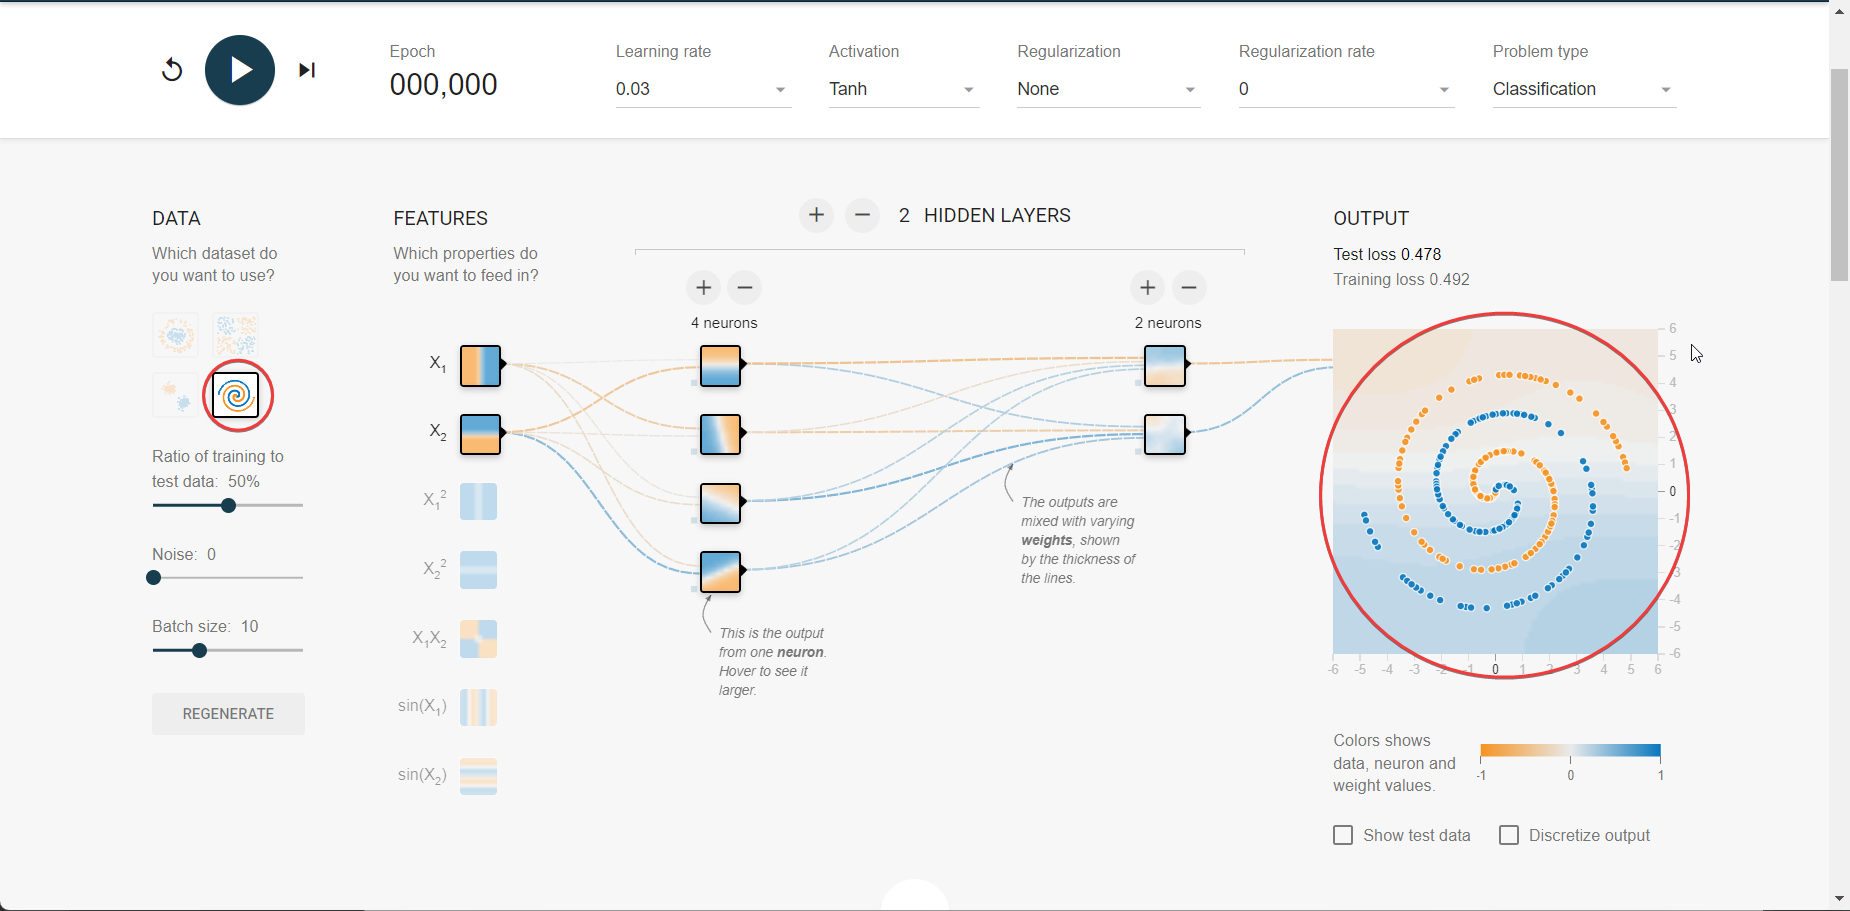

Coloque abaixo uma captura de tela da sua solução, mostrando a Test loss (no Colab, arraste a imagem para dentro de uma célula de texto ou use o botão de inserir imagem da barra da célula), e comente o que aprendeu neste exercício (qual o impacto do número de camadas, de neurônios em cada camada, da ativação, da taxa de aprendizado e da regularização).

*Escreva sua resposta aqui.*

## Aprendizados

- O custo de treino sozinho não mede generalização: é preciso um conjunto de validação, que não é usado para ajustar os pesos.
- Underfitting: custo alto no treino e na validação (modelo simples demais ou pouco treinado). Overfitting: custo de treino baixo e de validação alto, com o modelo seguindo o ruído.
- Early stopping para o treino na época de menor custo de validação; a regularização L2 soma $\frac{\lambda}{2}\|\boldsymbol{W}\|^2$ ao custo e mantém os pesos pequenos.
- O $\lambda$ é um hiperparâmetro: pequeno demais não evita o overfitting, grande demais leva ao underfitting. Ele é escolhido pelo custo de validação.
- O decaimento de pesos também está no treino dos LLMs: eles usam o AdamW, uma versão do otimizador Adam (outro otimizador, diferente do SGD usado aqui) em que o decaimento de pesos é aplicado separado do gradiente (Loshchilov e Hutter, 2019).

## Referências

- Christopher M. Bishop (2006). *Pattern Recognition and Machine Learning*. Springer. Capítulo 1 (ajuste de curva polinomial e regularização).
- [TensorFlow Playground](https://playground.tensorflow.org)
- [PyTorch: torch.optim.SGD (parâmetro weight_decay)](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html)
- [ipywidgets: Using Interact](https://ipywidgets.readthedocs.io/en/stable/examples/Using%20Interact.html)
- [Loshchilov, I.; Hutter, F. (2019). Decoupled Weight Decay Regularization (AdamW).](https://arxiv.org/abs/1711.05101)